## Lab: Market Return Dynamics

We will repeat the weather analysis using the stock market's daily percentage change, recorded in `market_return_pct` in `ff_market_daily.parquet`.

- **2** means the market gained 2% that day.
- **−2** means the market lost 2%.
- **0** means no change.

Use `market_return_pct` as it is. Each row is one trading day, so the next row is the next day the market was open.

**Does today's category help predict the next trading day's category?**


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd 

df = pd.read_parquet('../data/ff_market_daily.parquet')
df['date'] = pd.to_datetime(df['date'])
df = df.sort_values('date').reset_index(drop=True)

print(f"{len(df):,} trading-day observations: "
      f"{df['date'].min():%Y-%m-%d} to {df['date'].max():%Y-%m-%d}")
print(f"Are dates ordered? {df['date'].is_monotonic_increasing}")
df[['date', 'market_return_pct']].head()

26,296 trading-day observations: 1926-07-01 to 2026-07-31
Are dates ordered? True


,date,market_return_pct
0,1926-07-01,0.10
1,1926-07-02,0.46
2,1926-07-06,0.18
3,1926-07-07,0.10
4,1926-07-08,0.23


Here are plots of `market_return_pct`, as a kernel density plot and a time series.

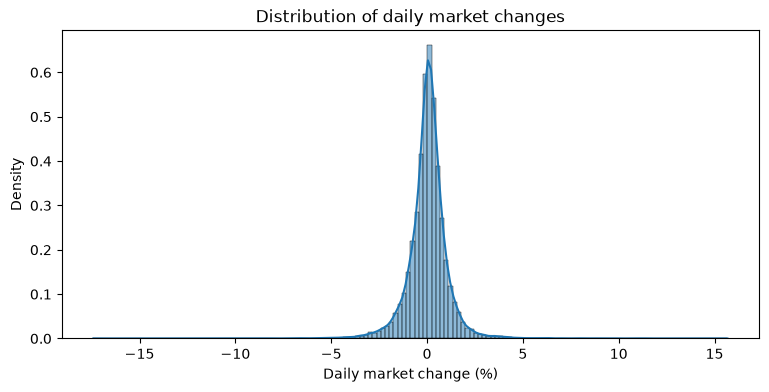

In [2]:
fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(data=df, x='market_return_pct', bins=150, stat='density', kde=True, ax=ax)
ax.set(xlabel='Daily market change (%)', title='Distribution of daily market changes')
plt.show()

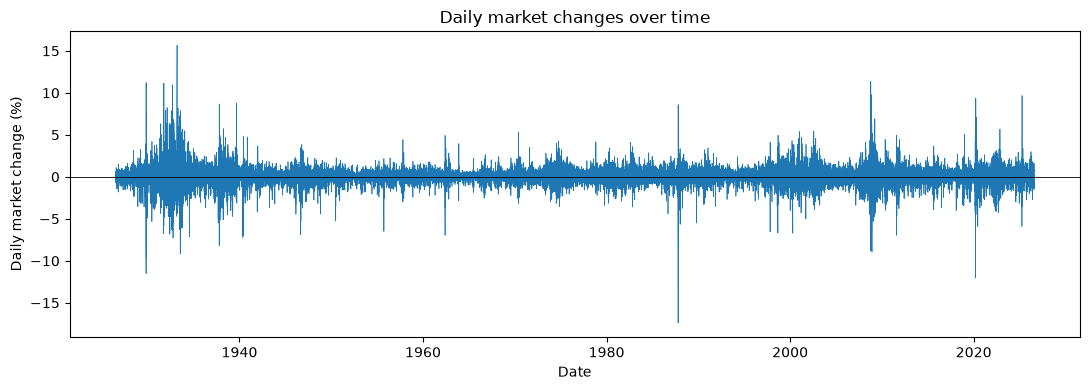

In [3]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(df['date'], df['market_return_pct'], linewidth=0.5)
ax.axhline(0, color='black', linewidth=0.6)
ax.set(xlabel='Date', ylabel='Daily market change (%)',
       title='Daily market changes over time')
fig.tight_layout()
plt.show()

### 1. Two States

- Start with two categories: **Up** for values greater than 0, and **Down (and flat)** for values less than or equal to 0. Create variables in your dataframe to capture the current and next value of `market_return_pct`.
- Pair today's category with the next trading day's category. Compute the joint PMF and marginals, and the conditional PMF. 
- Are up transitions more or less common than down transitions? 
- Are you more likely to transition to an Up day from a Down or Up day?

(Code below for analysis)

Are up transitions more or less common than down transitions? 
* Yes, up transitions are more common. If we look at the Joint PMF we can see that having Up to Up has a percentage of 32%. Juxtapose that with the down data - Down to Down = 22%. Going from Up to Down and Down to Up are equally likely at 23%. Additonally if we look at the marginal PMF we can see that the market goes up 55% of the time and down 45% of the time.

Are you more likely to transition to an Up day from a Down or Up day?
* You are more likely to transition to a up day after an up day. We see that on the Conditional PMF analysis that the when our state is up it stays up 58% of the time and when we are down we has a 50/50 chance to transition to Up day.

In [4]:
df['y_t'] = df['market_return_pct'] > 0
df['y_t'] = df['y_t'].map({True: 'Up', False: 'Down'})
df['y_tp1'] = df['y_t'].shift(-1)

In [5]:
Joint_PMF = pd.crosstab(df['y_t'], df['y_tp1'], normalize = True)
Joint_PMF

y_tp1,Down,Up
y_t,,
Down,0.224720,0.228142
Up,0.228142,0.318996


<Axes: xlabel='y_tp1', ylabel='y_t'>

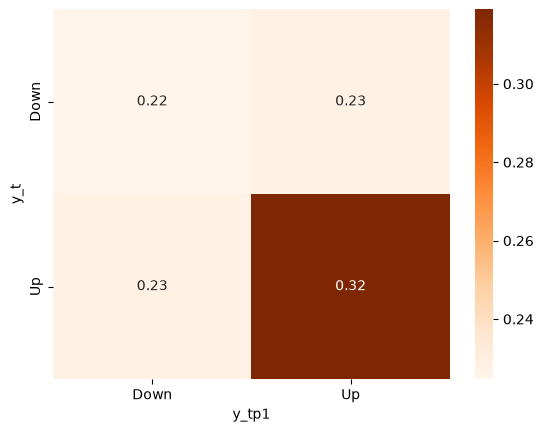

In [6]:
sns.heatmap(Joint_PMF, annot=True, fmt='.2f', cmap='Oranges')

In [7]:
Marginal_PMF = pd.crosstab(df['y_t'], df['y_tp1'], 
            normalize = True, margins = True)
Marginal_PMF

y_tp1,Down,Up,All
y_t,,,
Down,0.224720,0.228142,0.452862
Up,0.228142,0.318996,0.547138
All,0.452862,0.547138,1.000000


<Axes: xlabel='y_tp1', ylabel='y_t'>

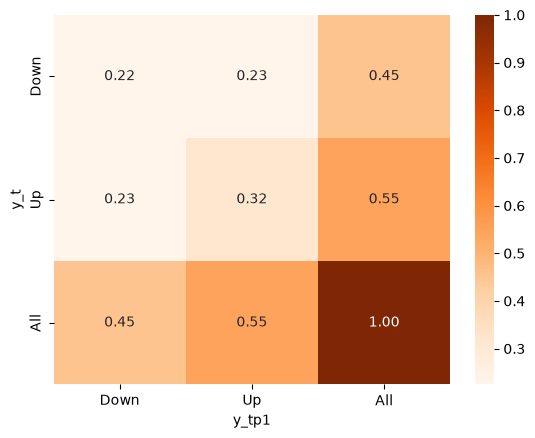

In [8]:
sns.heatmap(Marginal_PMF, annot=True, fmt='.2f', cmap='Oranges')

In [9]:
Conditional = pd.crosstab(df['y_t'], df['y_tp1'], 
            normalize = 'index')
Conditional

y_tp1,Down,Up
y_t,,
Down,0.496221,0.503779
Up,0.416974,0.583026


<Axes: xlabel='y_tp1', ylabel='y_t'>

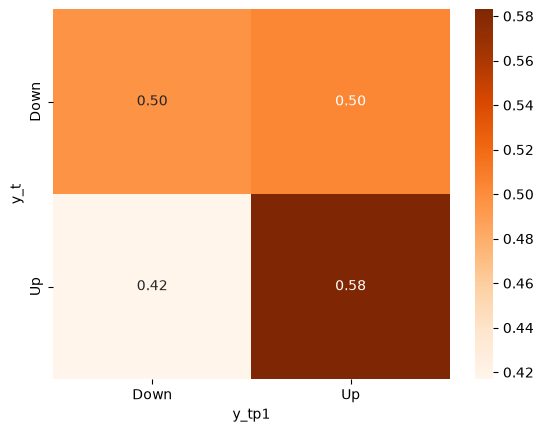

In [10]:
sns.heatmap(Conditional, annot=True, fmt='.2f', cmap='Oranges')

### 2. Binning a Continuous Variable

Now keep the sign and a coarse measure of the size of a daily log return:

| Category | Daily log return (%) |
| --- | --- |
| Large loss | $r \leq -1$ |
| Small loss | $-1 < r \leq -0.1$ |
| Near zero | $-0.1 < r \leq 0.1$ |
| Small gain | $0.1 < r \leq 1$ |
| Large gain | $r > 1$ |

For example, −2 belongs to **Large loss**, 0.05 to **Near zero**, and 0.8 to **Small gain**. These cutoffs are choices for this exercise. Each interval includes its upper endpoint; `-np.inf` and `np.inf` let the outer intervals include any size loss or gain.

- `pd.cut` to group `market_return_pct` into the five categories above. How many days fall into each of the five bins? Which are the most or least common?
- Compute the joint PMF and marginals. Which transitions are most likely to occur? 
- Compute the conditional PMF. For each current state, which two future states are the most likely? Subjectively, how close is each row to a uniform mass function with probability .2 over each transition? Is it relatively easy or difficult to predict the next state?
- For each state, compute the conditional expectation of tomorrow's `market_return_pct`. Given the current state, what are the expected percent returns for tomorrow? How do the min and max values for tomorrow vary across states? Which states have the highest standard deviation for tomorrow's percent returns? Describe any patterns in the volatility you notice. Using `.groupby` and `.describe` is the easiest way to do this. 

How many days fall into each of the five bins?Which are the most or least common?
* Following the order of Large Loss, Small Losee, Near Zero, Small Gain, and Large gain the days are [2759.0,7452.0,3441.0,9784.0, 2859.0]
* A small gain is the most common and a large loss is the least common.

Compute the joint PMF and marginals. Which transitions are most likely to occur?
* Small Gain to Small gain is the most likely to occur with a percentage of 16%. Additionally, small gain to small loss and small loss to small gain are equally likely to occur at 10%.

Compute the conditional PMF. For each current state, which two future states are the most likely? Subjectively, how close is each row to a uniform mass function with probability .2 over each transition? Is it relatively easy or difficult to predict the next state?
* For Large Gain the two most likely steps are: Small gain and Small Loss
* For Small Gain the two most likely steps are: Small gain and Small Loss
* For Near Zero the two most likely steps are: Small gain and Small Loss
* For Small Loss the two most likely steps are: Small gain and Small Loss
* For Large Loss the two most likely steps are: Small gain and Small Loss (nearly tied)

* Looking at the heat map and the conditional PMF we see that regardless of your previous state largely you are most likely to either have small gain (first) or a small loss (second). It varies per previous state but for the most part if you guessed that there would be a small gain after every previous state then you would be 37% likely to get guess correctly. However, that still isnt easy to guess and still gives you a 63% to guess incorrectly. Subjectively Large Loss would be the closest to a uniform distribution as the range of tomorrow probabilities, eith the exception of NZ, are above or very close to 0.2.

For each state, compute the conditional expectation of tomorrow's `market_return_pct`. Given the current state, what are the expected percent returns for tomorrow? How do the min and max values for tomorrow vary across states? Which states have the highest standard deviation for tomorrow's percent returns? Describe any patterns in the volatility you notice. Using `.groupby` and `.describe` is the easiest way to do this. 
* In order of Large Loss, Small Loss, Near Zero, Small Gain, and Large gain we see conditional expectations of [-0.04, -0.04, 0.02, 0.11, 0.16]%.
* We see the smallest varriation between Near Zero (approx 13 point range). We see the largest swing between our Large Loss & Large Gain (28 & 27 point swings respectively). 
* Following the largest swings we see that Large Loss and Large Gain have the largest standard deviations of 1.72 and 1.38 respectively. 
* I think it makes sense that are largest loss and largest gain catagories carry the largest min/max range and the largest standard deviation. This is because of volatilty clustersing. This means that our largest loss/gain days are likely to be followed by a another large loss/gain day. In contrast we are more likely to have a stable tomorrow when we had a stable day today (shown through a smaller SD from SL, NZ, and SG).


In [11]:
df['y_t'] = pd.cut(
    df['market_return_pct'],
    bins=[-np.inf, -1, -0.1, 0.1, 1, np.inf],
    labels=['Large loss', 'Small loss', 'Near zero', 'Small gain', 'Large gain']
)
df['y_tp1'] = df['y_t'].shift(-1)
df['y_t'].value_counts()


y_t
Small gain    9785
Small loss    7452
Near zero     3441
Large gain    2859
Large loss    2759
Name: count, dtype: int64

In [12]:
Joint_PMF = pd.crosstab(df['y_t'], df['y_tp1'], normalize = True)
Marginal_PMF = pd.crosstab(df['y_t'], df['y_tp1'], 
            normalize = True, margins = True)
print(Joint_PMF)

y_tp1       Large loss  Small loss  Near zero  Small gain  Large gain
y_t                                                                  
Large loss    0.021335    0.027191   0.009051    0.027800    0.019547
Small loss    0.035444    0.088648   0.034151    0.097775    0.027382
Near zero     0.009317    0.041985   0.020955    0.049325    0.009279
Small gain    0.024986    0.100057   0.055029    0.159422    0.032592
Large gain    0.013843    0.025518   0.011637    0.037802    0.019928


In [13]:
print(Marginal_PMF)

y_tp1       Large loss  Small loss  Near zero  Small gain  Large gain  \
y_t                                                                     
Large loss    0.021335    0.027191   0.009051    0.027800    0.019547   
Small loss    0.035444    0.088648   0.034151    0.097775    0.027382   
Near zero     0.009317    0.041985   0.020955    0.049325    0.009279   
Small gain    0.024986    0.100057   0.055029    0.159422    0.032592   
Large gain    0.013843    0.025518   0.011637    0.037802    0.019928   
All           0.104925    0.283400   0.130823    0.372124    0.108728   

y_tp1            All  
y_t                   
Large loss  0.104925  
Small loss  0.283400  
Near zero   0.130861  
Small gain  0.372086  
Large gain  0.108728  
All         1.000000  


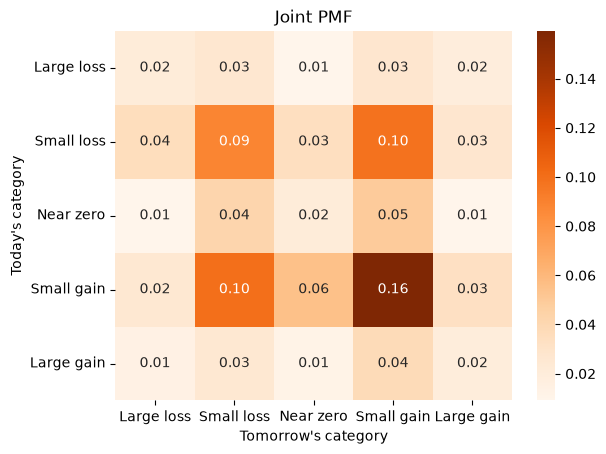

In [14]:
ax = sns.heatmap(Joint_PMF, annot=True, fmt='.2f', cmap='Oranges')
ax.set(xlabel="Tomorrow's category", ylabel="Today's category", title='Joint PMF')
plt.show()

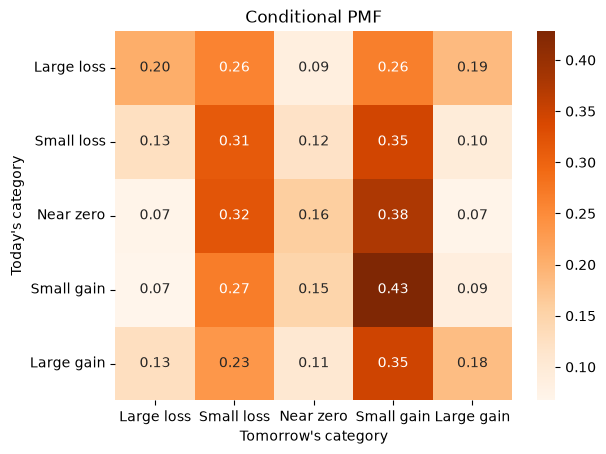

In [15]:
Conditional = pd.crosstab(df['y_t'], df['y_tp1'], normalize='index')
ax = sns.heatmap(Conditional, annot=True, fmt='.2f', cmap='Oranges')
ax.set(xlabel="Tomorrow's category", ylabel="Today's category", title='Conditional PMF')
plt.show()


In [16]:
#continous expectation calculation
df['MKTRP_tp1'] = df['market_return_pct'].shift(-1)
Conditional_Expectation = df.groupby('y_t', observed = False)['MKTRP_tp1'].describe()
Conditional_Expectation

,count,mean,std,min,25%,50%,75%,max
y_t,,,,,,,,
Large loss,2759.0,-0.038311,1.720570,-17.41,-0.79,-0.01,0.72,11.22
Small loss,7452.0,-0.043814,1.009529,-11.23,-0.53,0.01,0.45,11.36
Near zero,3441.0,0.015013,0.826054,-8.19,-0.35,0.03,0.42,5.49
Small gain,9784.0,0.106810,0.832186,-8.25,-0.25,0.12,0.50,8.67
Large gain,2859.0,0.163092,1.384086,-12.00,-0.37,0.15,0.73,15.67


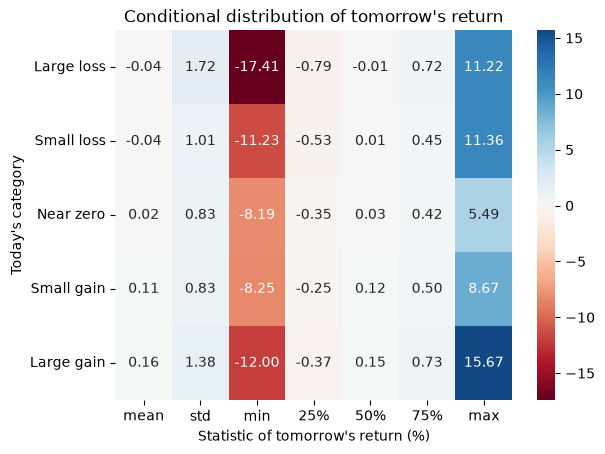

In [17]:
ax = sns.heatmap(Conditional_Expectation.drop(columns='count'),
                 annot=True, fmt='.2f', cmap='RdBu', center=0)
ax.set(xlabel="Statistic of tomorrow's return (%)", ylabel="Today's category",
       title="Conditional distribution of tomorrow's return")
plt.show()


### 3. Scaling up

The choice of five bins was arbitrary. For more realistic or complex models, we'd want to flexibly choose the number of bins. Instead of the five bins from above, we'll break the data into 21 equally spaced bins based on quantile; the qualitative results hold up for 11 or 71 or 101, but 21 is interpretable and easier to manage.

- Use `pd.qcut` to assign the data into 21 bins, and add that variable to the dataframe as `df[y_t]`. Use `.shift(-1)` to create `df[y_tp1]`. 
- Compute the joint PMF. Plot it as a heatmap. Do you see any obvious patterns? Explain. Try subtracting 1/21**2 from the PMF before plotting it, to normalize away the uniform PMF, and see systematic deviations from uniformly random behavior.
- Compute the conditional PMF. Plot it as a heatmap. Do you see any obvious patterns? Explain. Try subtracting 1/21 from the PMF before plotting it, to normalize away the uniform PMF, and see systematic deviations from uniformly random transitions.
- For each bin, compute the next day's minimum, mean, and maximum values. Plots these as lines on a graph against the bins. Do you see any obvious patterns? Explain. 
- For each bin, compute the next day's standard deviation, and plot it as a line graph against the bins. Do you see any obvious patterns? Explain. 
- How easy is it to predict the market?

In [18]:
df['y_t'] = pd.qcut(df['market_return_pct'], q=21, labels=False)
df['y_tp1'] = df['y_t'].shift(-1)


In [19]:
#Creating my Joint PMF with the 21 bins
tab2 = pd.crosstab(df['y_t'], df['y_tp1'], normalize = True)
Tab2_minus_uniform = tab2 - (1/(21**2))


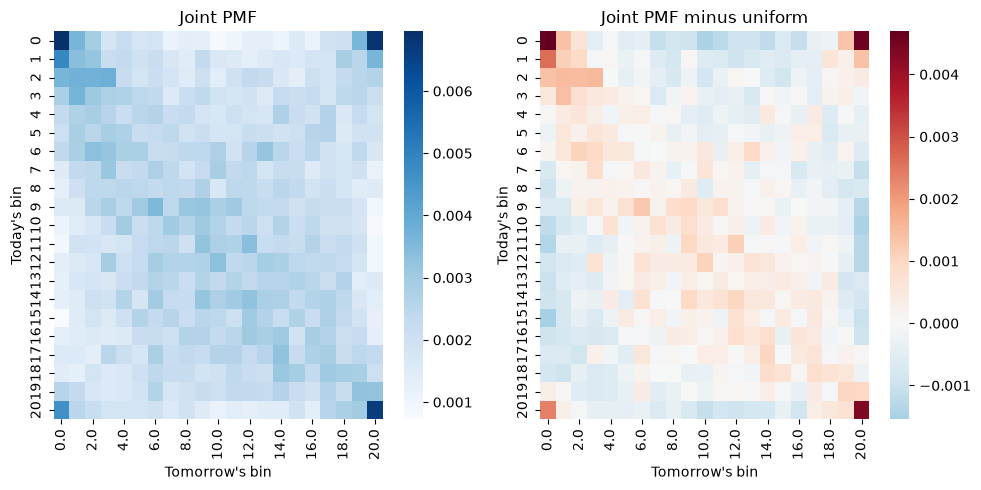

In [20]:
#Joint PMF graphs - claude helped me combined it into a subplot
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

sns.heatmap(tab2, cmap='Blues', ax=axes[0])
axes[0].set(title='Joint PMF', xlabel="Tomorrow's bin", ylabel="Today's bin")

sns.heatmap(Tab2_minus_uniform, cmap='RdBu_r', center=0, ax=axes[1])
axes[1].set(title='Joint PMF minus uniform', xlabel="Tomorrow's bin", ylabel="Today's bin")

fig.tight_layout()
plt.show()


Compute the joint PMF. Plot it as a heatmap. Do you see any obvious patterns? Explain. Try subtracting 1/21**2 from the PMF before plotting it, to normalize away the uniform PMF, and see systematic deviations from uniformly random behavior.
* All of the corners contain high probability. The 4 corners are from pairs that are identical and opposite to the previous day. For example, on of the highest probabilities on our joint PMF is  that we have one of our lowest returns and on Y_tp1 a day of our highest return occurs. This is the same pattern we saw before (volatility clustering): extremes follow extremes, but the direction is hard to predict. Lastly, the lowest probabilities are where an extreme day is paired with a middle (near-zero) day, so a big move is rarely followed by a quiet day.

In [21]:
Q3_Conditional = pd.crosstab(df['y_t'], df['y_tp1'], normalize='index')

Q3_Conditional_deuniformed = Q3_Conditional -  (1/(21))
print(Q3_Conditional)

y_tp1      0.0       1.0       2.0       3.0       4.0       5.0       6.0   \
y_t                                                                           
0      0.145817  0.076494  0.061355  0.037450  0.046215  0.036653  0.038247   
1      0.102155  0.071030  0.067039  0.046289  0.048683  0.041500  0.046289   
2      0.074650  0.076983  0.076205  0.077760  0.045879  0.038103  0.043546   
3      0.057813  0.075781  0.063281  0.057031  0.055469  0.050781  0.048438   
4      0.049593  0.057724  0.061789  0.055285  0.045528  0.054472  0.056098   
5      0.044046  0.061175  0.053834  0.061990  0.058728  0.047308  0.048940   
6      0.045952  0.053975  0.064187  0.061269  0.053975  0.053975  0.042305   
7      0.033167  0.051410  0.053068  0.068823  0.047264  0.051410  0.060531   
8      0.029215  0.044240  0.053422  0.053422  0.055092  0.054257  0.050918   
9      0.031555  0.030804  0.050338  0.056349  0.048084  0.059354  0.069872   
10     0.023967  0.031405  0.037190  0.047107  0.064

In [22]:
print(Q3_Conditional_deuniformed)

y_tp1      0.0       1.0       2.0       3.0       4.0       5.0       6.0   \
y_t                                                                           
0      0.098198  0.028875  0.013736 -0.010169 -0.001404 -0.010966 -0.009372   
1      0.054536  0.023410  0.019420 -0.001330  0.001064 -0.006119 -0.001330   
2      0.027031  0.029364  0.028586  0.030141 -0.001740 -0.009516 -0.004073   
3      0.010193  0.028162  0.015662  0.009412  0.007850  0.003162  0.000818   
4      0.001974  0.010105  0.014170  0.007666 -0.002091  0.006852  0.008479   
5     -0.003573  0.013556  0.006215  0.014371  0.011109 -0.000311  0.001321   
6     -0.001667  0.006356  0.016568  0.013650  0.006356  0.006356 -0.005314   
7     -0.014452  0.003791  0.005449  0.021204 -0.000355  0.003791  0.012912   
8     -0.018404 -0.003379  0.005803  0.005803  0.007473  0.006638  0.003299   
9     -0.016064 -0.016815  0.002719  0.008730  0.000465  0.011735  0.022253   
10    -0.023652 -0.016214 -0.010429 -0.000512  0.016

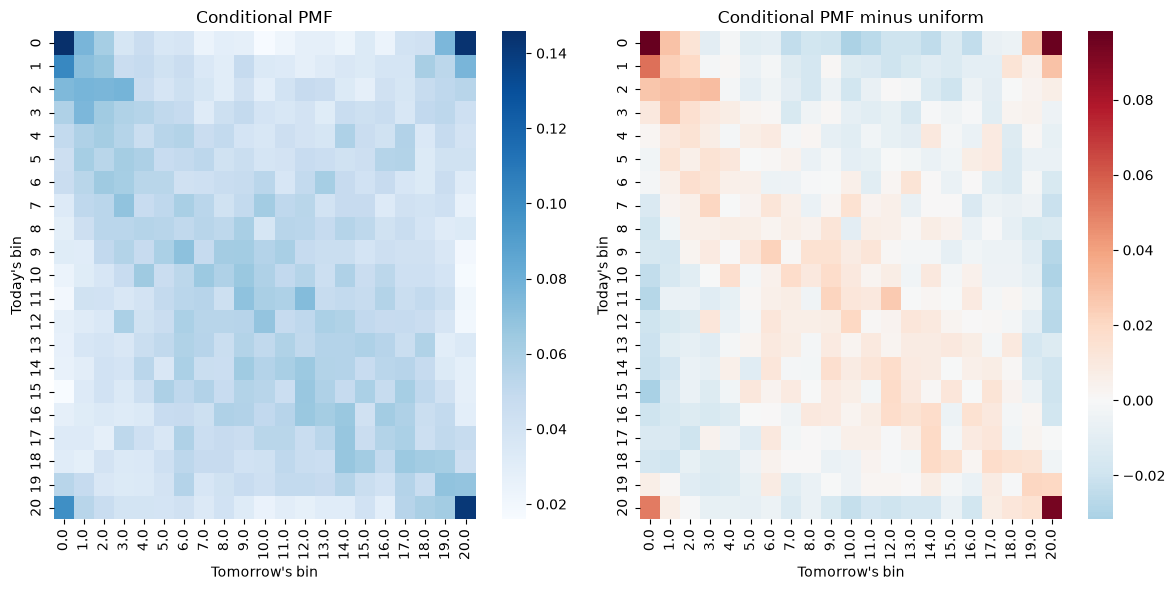

In [23]:
#Conditional PMF Graphs - did these ones on my own
fig, axes = plt.subplots(1,2, figsize = (12,6))

sns.heatmap(Q3_Conditional, cmap = 'Blues', ax=axes[0])
axes[0].set(title='Conditional PMF', xlabel="Tomorrow's bin", ylabel="Today's bin")

sns.heatmap(Q3_Conditional_deuniformed, cmap='RdBu_r', center=0, ax=axes[1])
axes[1].set(title='Conditional PMF minus uniform', xlabel="Tomorrow's bin", ylabel="Today's bin")

fig.tight_layout()
plt.show()

Compute the conditional PMF. Plot it as a heatmap. Do you see any obvious patterns? Explain. Try subtracting 1/21 from the PMF before plotting it, to normalize away the uniform PMF, and see systematic deviations from uniformly random transitions.
* The conditonal PMF exhibits the same volatility clustering of the joint PMF. Extremes are the most likely to follow each other, we will likely see a bin 20 value followed by a bin 0 value or another bin 20 value (and vice-versa). We will likely not see an extreme day followed by a bin 5 through 15 day. Additionally, because our bin 5-15 values are close to uniform it is harder to predict what will happen tomorrow.


In [24]:
df['MKTRP_tp1'] = df['market_return_pct'].shift(-1)
Q3_stats = df.groupby('y_t')['MKTRP_tp1'].agg(['min', 'mean', 'max', 'std'])
Q3_stats

,min,mean,max,std
y_t,,,,
0,-17.41,-0.013713,11.22,2.140465
1,-7.36,-0.076712,6.36,1.285882
2,-8.79,-0.097084,11.36,1.227976
3,-8.28,-0.058594,6.16,1.049607
4,-6.89,-0.024211,4.56,0.989470
5,-11.23,-0.022692,6.37,1.024761
6,-3.94,-0.030241,7.37,0.930389
7,-3.40,-0.014303,4.76,0.835663
8,-6.00,0.025860,5.49,0.853220


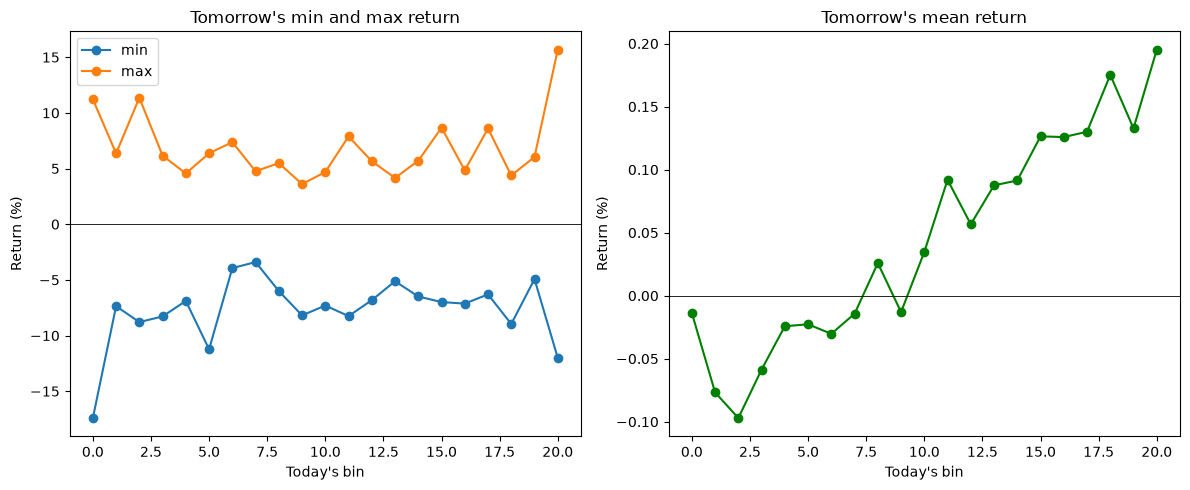

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

Q3_stats[['min', 'max']].plot(marker='o', ax=axes[0])
axes[0].axhline(0, color='black', linewidth=0.6)
axes[0].set(title="Tomorrow's min and max return", xlabel="Today's bin", ylabel="Return (%)")

Q3_stats['mean'].plot(marker='o', color='green', ax=axes[1])
axes[1].axhline(0, color='black', linewidth=0.6)
axes[1].set(title="Tomorrow's mean return", xlabel="Today's bin", ylabel="Return (%)")

fig.tight_layout()
plt.show()

For each bin, compute the next day's minimum, mean, and maximum values. Plots these as lines on a graph against the bins. Do you see any obvious patterns? Explain. 
* We see the same patterns that we saw earlier in Q3. We are observing volatitlity clustering and these metrics reinforce that conclusion. The largest loss or gain tomorrow happens at todays bins 0 & 20, the extremes of the data set. Additionally, the distance between the mins andnmax at bins 0&20 are the largest in the dataset. Also around bin 10 we are seeing relatively modest ROR for the min/max. When we look at the mean we see that it climbs from left to right and from -.1 to 0.2 centering at 0 at bin 10. We know that these massive RORs are occuring according to our min/max graph but when we look at the mean graph we see that the ROR higs close to zero for every bin, this tells me that no matter what when given todays rate of return we have a hard time making a prediction about tomorrow. 

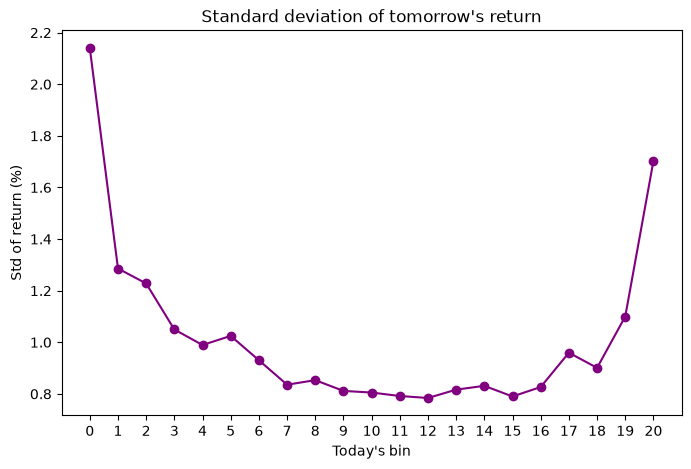

In [26]:
fig, ax = plt.subplots(figsize=(8, 5))

Q3_stats['std'].plot(marker='o', color='purple', ax=ax)
ax.set(title="Standard deviation of tomorrow's return", xlabel="Today's bin", ylabel="Std of return (%)")
ax.set_xticks(range(21))

plt.show()

For each bin, compute the next day's standard deviation, and plot it as a line graph against the bins. Do you see any obvious patterns? Explain.
* We see how volatility clustering effects our metrics. It is present again in the standard deviation and like questions 2 I think it makes sense that we have the largest Standard deviations after a bin 0 or 20 day. This is because our largest loss/gain days are most likely to be followeds by another large gain/loss day and thus the difference between each successive day wil be extremely large. Compare that to bin 10, which is a near zero bin, and we see that the standard deviation is much lower. This is because days near zero are likely to be followed by another day near zero thus comparessing the standard deviation.
How easy is it to predict the market?
* I think it is really hard to predict it with any level of success. The mean graph (above) was the most telling for me. I had written alot about how the big days often are followed by other big ays but when you look at the mean of those days you there isnt a massive disparity between the RoR on an extreme day and a bin 10 day. 